In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

from matplotlib.collections import LineCollection
from matplotlib import colors as mcolors
import scipy
import h5py

In [4]:
rows = []
for mouse in ['cm229','cm128','cm126']:
    load_path = str(FIGURES / "figureS8") + "/"
    fve_scores = load_pickle(load_path+'fve_scores_forward_pass_'+mouse)
    
    for score in fve_scores:
        rows.append({'mouse': mouse, 'FVE': score})
        
# Convert the list of rows into a DataFrame
df_fve = pd.DataFrame(rows)

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:26: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations


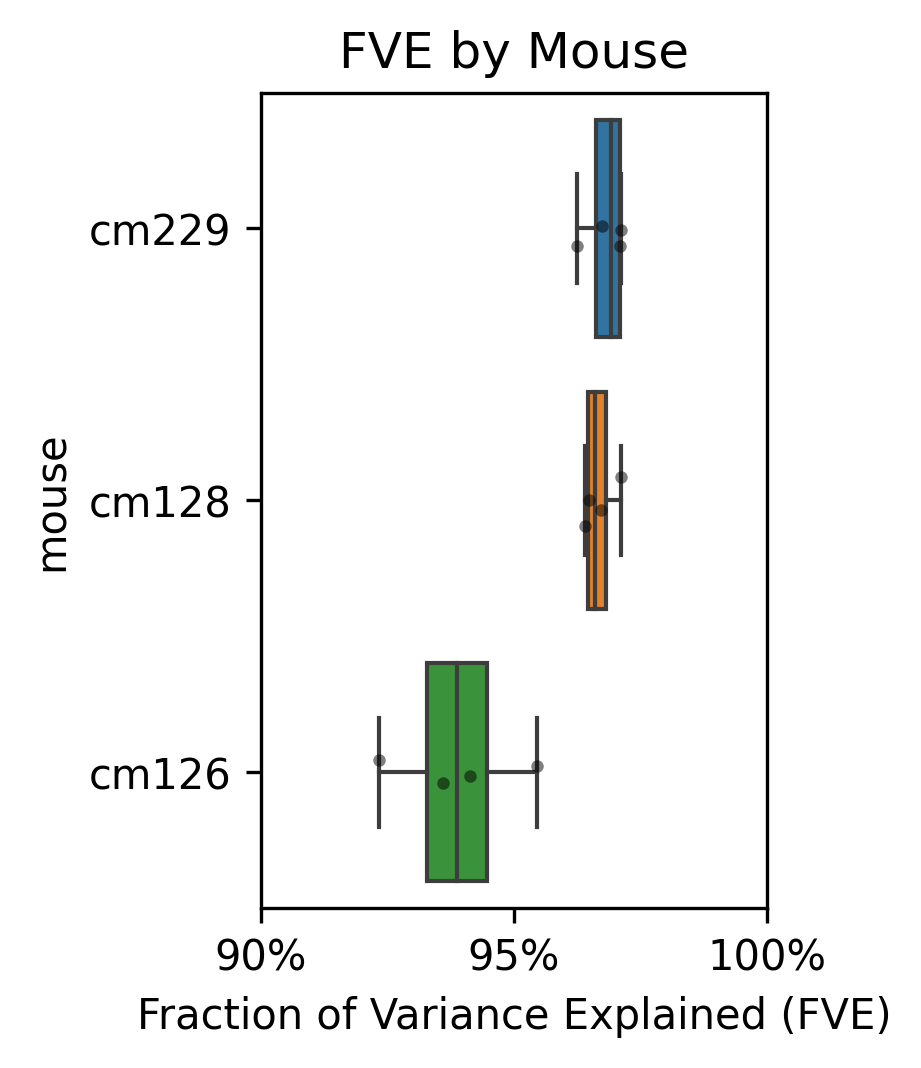

In [10]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)


plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(45,45),dpi=300)

y_offset = 20;x_offset=20;

y_start = y_offset; y_stop = y_start+8
x_start = x_offset; x_stop = x_start+5

ax0 = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])

sns.boxplot(data=df_fve, y='mouse', x='FVE', orient='h',linewidth=1,showfliers=False)
sns.stripplot(data=df_fve, y='mouse', x='FVE', color='black', 
              alpha=0.5, jitter=0.1, size=3,ax=ax0)

ax0.set_xlabel("Fraction of Variance Explained (FVE)")
ax0.set_title("FVE by Mouse")
ax0.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout()
ax0.set_xlim(0.9,1)
ax0.set_xticks([0.9,0.95,1])
plt.savefig('figS8-forward-pass-FAE.svg',format='svg',dpi=300)

# backward pass FVE

In [12]:
import os
# --- Setup ---
# Define the path to your data directory
data_path = str(FIGURES / "movie8") + "/" 

# List of behaviors you want to process
behavior_types = ['run', 'lick', 'integrated']

# Initialize the dictionary to store results
dict_fve = {}

# --- Main Loop ---
# Loop over each behavior type
for behavior in behavior_types:
    
    # Create a search pattern to find all files for the current behavior
    search_pattern = os.path.join(data_path, f'{behavior}-single-trial-cm*')
    bout_files = glob.glob(search_pattern)
    
    # This list will hold ALL FVE values from ALL bouts across ALL files for this behavior
    all_fves_for_behavior = []
    
    print(f"--- Processing behavior: {behavior} ({len(bout_files)} files found) ---")
    
    # Loop over each found file (each mouse)
    for file_path in bout_files:
        # try:
        # Load the 4D data for one mouse
        data = load_pickle(file_path)
        residual_all_bouts = data['residuals']       # Shape: (256, 256, 53, 18)
        full_jrgeco_all_bouts = data['full_jrgeco'] # Shape: (256, 256, 53, 18)

        # Get the number of bouts from the last dimension of the array
        num_bouts = residual_all_bouts.shape[3]

        # --- NEW: Loop through each bout within the file ---
        for i in range(num_bouts):
            # Slice the arrays to get data for just ONE bout
            # The '...' means "take all previous dimensions"
            residual_one_bout = residual_all_bouts[..., i]
            full_jrgeco_one_bout = full_jrgeco_all_bouts[..., i]

            # Calculate FVE for this single bout, ignoring NaNs
            numerator = np.nansum(residual_one_bout**2)
            denominator = np.nansum(full_jrgeco_one_bout**2)

            if denominator == 0:
                fve = np.nan
            else:
                fve = 1 - (numerator / denominator)

            # Add the single-bout FVE to our master list for this behavior
            all_fves_for_behavior.append(fve)

#         except Exception as e:
#             print(f"Could not process file {os.path.basename(file_path)}: {e}")
            
    # Store the master list of FVEs in the main dictionary
    dict_fve[behavior] = all_fves_for_behavior

# --- Results ---
print("\n--- FVE Calculation Complete ---")
for behavior, fve_list in dict_fve.items():
    avg_fve = np.nanmean(fve_list)
    print(f"Behavior '{behavior}': Found {len(fve_list)} total bouts with an average FVE of {avg_fve:.3f}")




--- Processing behavior: run (3 files found) ---
--- Processing behavior: lick (3 files found) ---
--- Processing behavior: integrated (3 files found) ---

--- FVE Calculation Complete ---
Behavior 'run': Found 71 total bouts with an average FVE of 0.952
Behavior 'lick': Found 43 total bouts with an average FVE of 0.890
Behavior 'integrated': Found 38 total bouts with an average FVE of 0.935


In [13]:
df_fve = pd.DataFrame(dict_fve.items(), columns=['behavior', 'FVE']).explode('FVE')




/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:26: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations


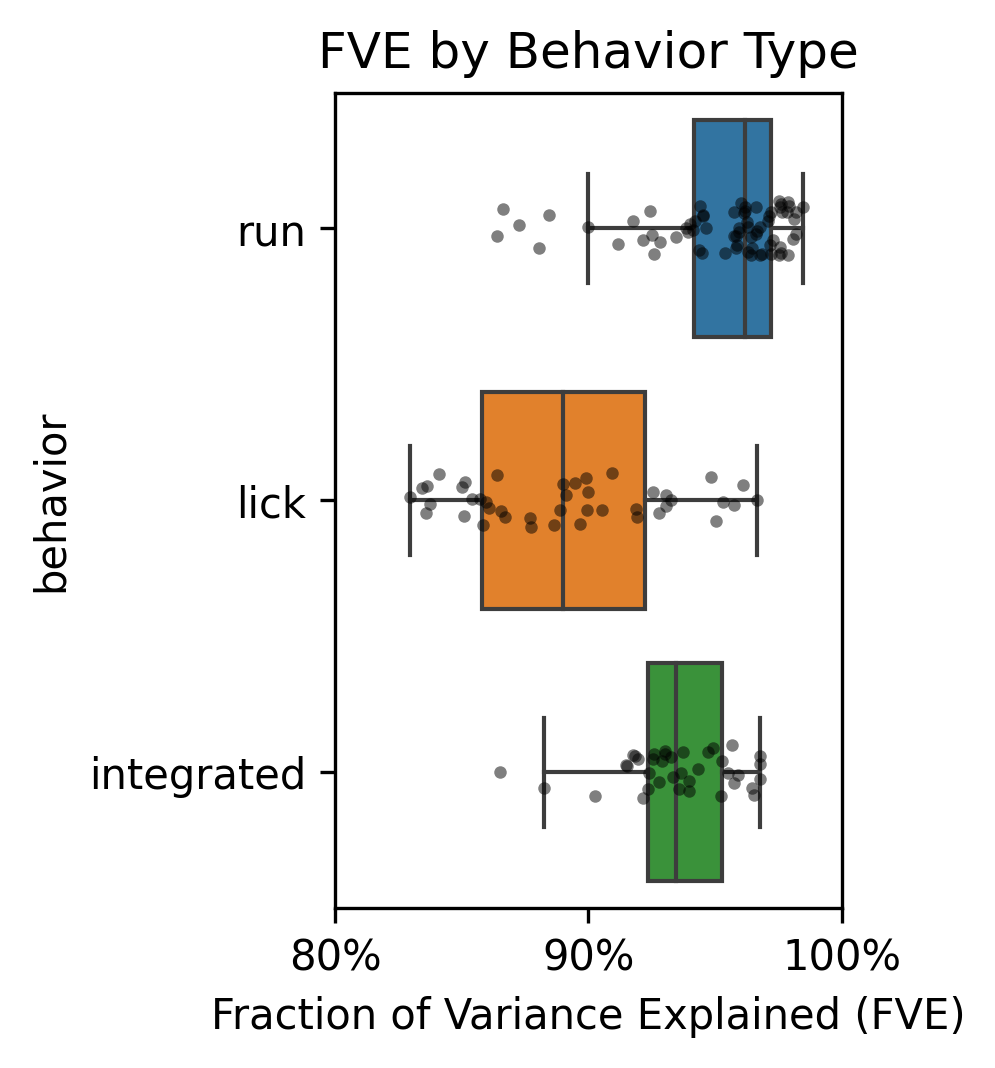

In [15]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)


plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(45,45),dpi=300)

y_offset = 20;x_offset=20;

y_start = y_offset; y_stop = y_start+8
x_start = x_offset; x_stop = x_start+5

ax0 = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])

sns.boxplot(data=df_fve, y='behavior', x='FVE', orient='h',linewidth=1,showfliers=False)
sns.stripplot(data=df_fve, y='behavior', x='FVE', color='black', 
              alpha=0.5, jitter=0.1, size=3,ax=ax0)

ax0.set_xlabel("Fraction of Variance Explained (FVE)")
ax0.set_title("FVE by Behavior Type")
ax0.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout()
ax0.set_xlim(0.8,1)
ax0.set_xticks([0.8,0.9,1])
plt.savefig('figS8-backward pass FVE-behavior-types.svg',format='svg',dpi=300)


In [7]:
def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
        return pickle_model

In [24]:
# load_model(CLS_root+'dict_results_corr_'+'cm126')

cm229 0.5714285714285714
cm229 0.5714285714285714
cm229 0.5714285714285714
cm229 0.6428571428571428
cm128 0.42857142857142855
cm128 0.42857142857142855
cm128 0.5
cm128 0.42857142857142855
cm126 0.6428571428571428
cm126 0.5714285714285714
cm126 0.6428571428571428
cm126 0.6428571428571428


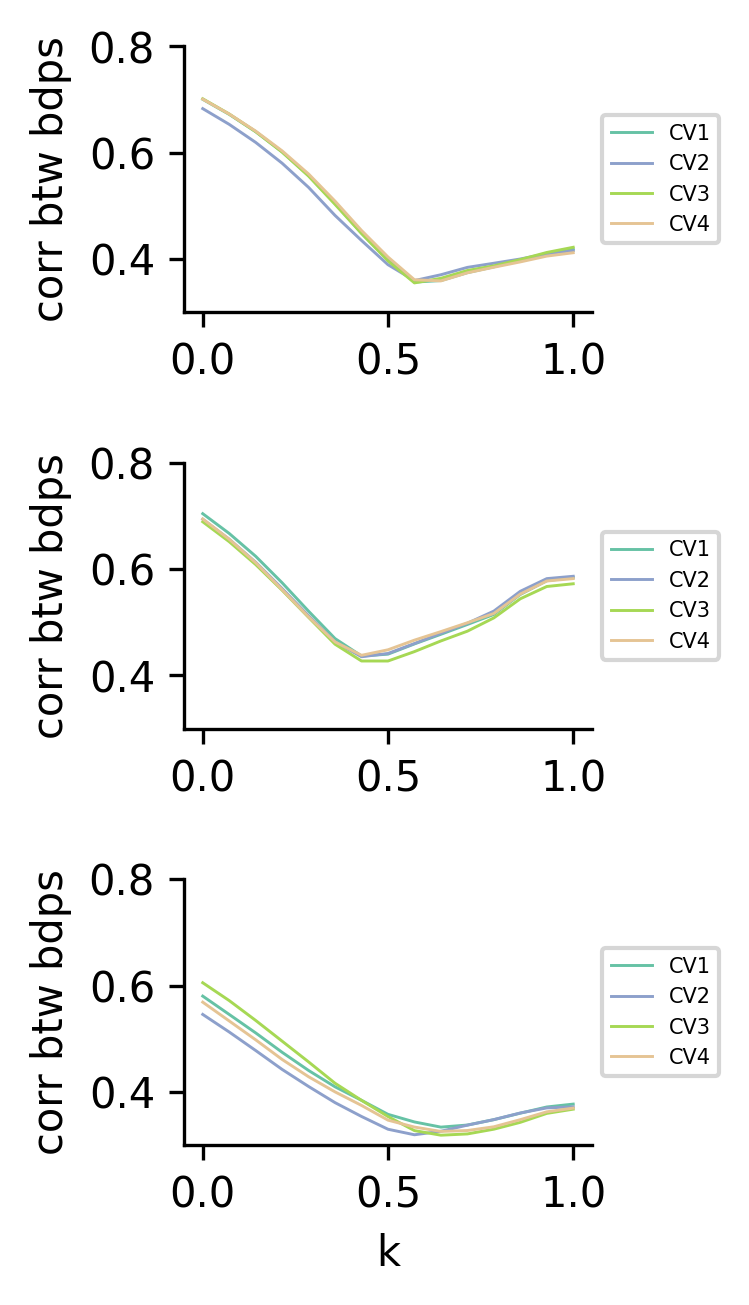

In [9]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)


plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

y_start = y_offset; y_stop = y_start+4
x_start = x_offset; x_stop = x_start+6

for i_ax in range(3):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop + 2
    y_stop = y_start+4
    
temp_colors = sns.color_palette("Set2")
for i_ax,mouse in enumerate(['cm229','cm128','cm126']):
    ks = dict_ks[mouse]
    dict_score_corr_here = dict_score_corr[mouse]
    for i_fold in range(4):
        exec("ax{}.plot(ks,dict_score_corr_here[i_fold],color=temp_colors[i_fold*2],label='CV'+str(i_fold+1),linewidth=0.7)".format(i_ax))
        print(mouse,ks[np.argmin(dict_score_corr_here[i_fold])])
    exec("ax{}.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=5)".format(i_ax))
    exec("ax{}.set_ylabel('corr btw bdps');".format(i_ax))
    if i_ax == 2:
        exec("ax{}.set_xlabel('k')".format(i_ax))
    exec("ax{}.set_ylim([0.3,0.8])".format(i_ax))

    for axis in ['top','right']:
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))

plt.savefig('figS8-corr-against-k-{}.svg'.format(mouse),format='svg',dpi=300)

# CLS spatial

In [41]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
palatte_dict['RALM'] = palatte_dict['ALM']
palatte_dict['LALM'] = palatte_dict['RALM']  #'bisque'
palatte_dict['RRSP'] = palatte_dict['RSP']
palatte_dict['LRSP'] = palatte_dict['RRSP']  #'sandybrown'

palatte_dict['RFP_M1_extra'] = palatte_dict['LFP']
palatte_dict['LFP_M1_extra'] = palatte_dict['LFP']

palatte_dict['RholeMOp'] = '#ff964f' #pastel orange
palatte_dict['LholeMOp'] = '#ff964f' #pastel orange

palatte_dict['RT'] =  '#b1d27b' # pale olive
palatte_dict['LT'] =  '#b1d27b' # pale olive

palatte_dict['LV'] =  palatte_dict['RV']

palatte_dict['Rposterior'] = 'palegreen' #'greenyellow'
palatte_dict['Lposterior'] = 'palegreen' #'greenyellow'

body_part_short_dict = {'RFP_':'FP(R,','LFP_':'FP(L,',
                        'RHP_':'HP(R,','LHP_':'HP(L,',
                        'RW_':'whisker(R,','LW_':'whisker(L,',
                        'RM_':'mouth(R,','LM_':'mouth(L,',
                        'RV_':'visual(R,','LV_':'visual(L,',
                        'RN_':'nose(R,','LN_':'nose(L,',
                        'RT_':'tail(R,','LT_':'tail(L,',
                        
                         'RV':'visual(R)','LV':'visual(L)',
                        'RALM':'lateral_1(R)','LALM':'lateral_1(L)',
                        'RRSP':'RSP(R)','LRSP':'RSP(L)',
                        'RFP_M1_extra':'FL(R,S1)','LFP_M1_extra':'FL(L,S1)',
                        'RholeMOp':'unDef_1(R)','LholeMOp':'unDef_1(L)',
                        'Rposterior':'unDef_2(R)','Lposterior':'unDef_2(L)',
                       }

In [11]:
all_bdps_list_S1 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RT','LFP', 'LHP',  'LW', 'LM', 'LN','LT']
all_bdps_list_M2 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RV','LFP', 'LHP',  'LW', 'LM', 'LN','LV']
all_bdps_list_M1 = [ 'RFP', 'RHP', 'LFP', 'LHP']
all_bdps_extra = ['RALM','LALM', 'RV', 'LV','RRSP','LRSP','RFP_M1_extra','LFP_M1_extra', 
                 'RholeMOp','LholeMOp',
                 'Rposterior','Lposterior'
                 ]
all_bdps_S1 = [bdp+'_S1' for bdp in all_bdps_list_S1]
all_bdps_M2 = [bdp+'_M2' for bdp in all_bdps_list_M2]
all_bdps_M1 = [bdp+'_M1' for bdp in all_bdps_list_M1]

all_bdps = all_bdps_extra + all_bdps_M2 + all_bdps_S1 + all_bdps_M1

In [31]:
mouse = 'cm229'
save_dict = load_pickle(CLS_root+'M2S1M1_NNLS_spatial_'+mouse)
all_bdps_w_order = save_dict['all_bdps_w_order']
full_M = save_dict['full_M']
# mask_M2 = save_dict['mask_M2']

with h5py.File(figure_config_root+'mask_midline_v2_'+mouse+'.mat','r') as f_midline:
        mask_midline = np.array(f_midline['mask_midline']).T
        
full_data_root = str(FIGURES / "movie8") + "/"  
dict_st_movie_save = load_pickle(full_data_root+'run-single-trial-'+mouse)
full_jrgeco = dict_st_movie_save['full_jrgeco']
mask_new = full_M.reshape((256,256,len(all_bdps)))[:,:,0]>-100
mask_new=mask_new.astype(float)
mask_new[mask_new==0]=np.nan

mask = np.nanmean(np.nanmean(full_jrgeco,-1),-1)>-1
mask = mask.astype(float)
mask[mask==0]=np.nan

mask = np.multiply(mask,mask_new)>-100
mask = mask.astype('float')
mask[mask==0]=np.nan

mask_reshape = mask.reshape((256*256))

W_S1M2M1 = full_M[mask_reshape==1,:]

# W_masked_S1M2M1 = np.zeros((256*256,W_S1M2M1.shape[-1]));W_masked_S1M2M1[:]=np.nan
# W_masked_S1M2M1[mask_reshape==1,:] = W_S1M2M1
# W_masked_S1M2M1 = W_masked_S1M2M1.reshape((256,256,-1))

# add M2 ones
W_S1M2M1_M2 = []
for i_key,key in enumerate(all_bdps_M2):
    ind_in_list = all_bdps.index(key)
    W_S1M2M1_M2.append(W_S1M2M1[:,ind_in_list])
W_S1M2M1_M2_sum = np.clip(np.sum(np.stack(W_S1M2M1_M2,0),0), 0, 1)
W_S1M2M1 = np.append(W_S1M2M1,W_S1M2M1_M2_sum[:,np.newaxis],axis=1)
# add cortical ones
W_S1M2M1 = np.append(W_S1M2M1,np.ones((len(W_S1M2M1_M2_sum),1)),axis=1)

W_masked = np.zeros((256*256,W_S1M2M1.shape[-1]));W_masked[:]=np.nan
W_masked[mask_reshape==1,:] = W_S1M2M1
W_masked = W_masked.reshape((256,256,-1))


/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:17: RuntimeWarning: Mean of empty slice


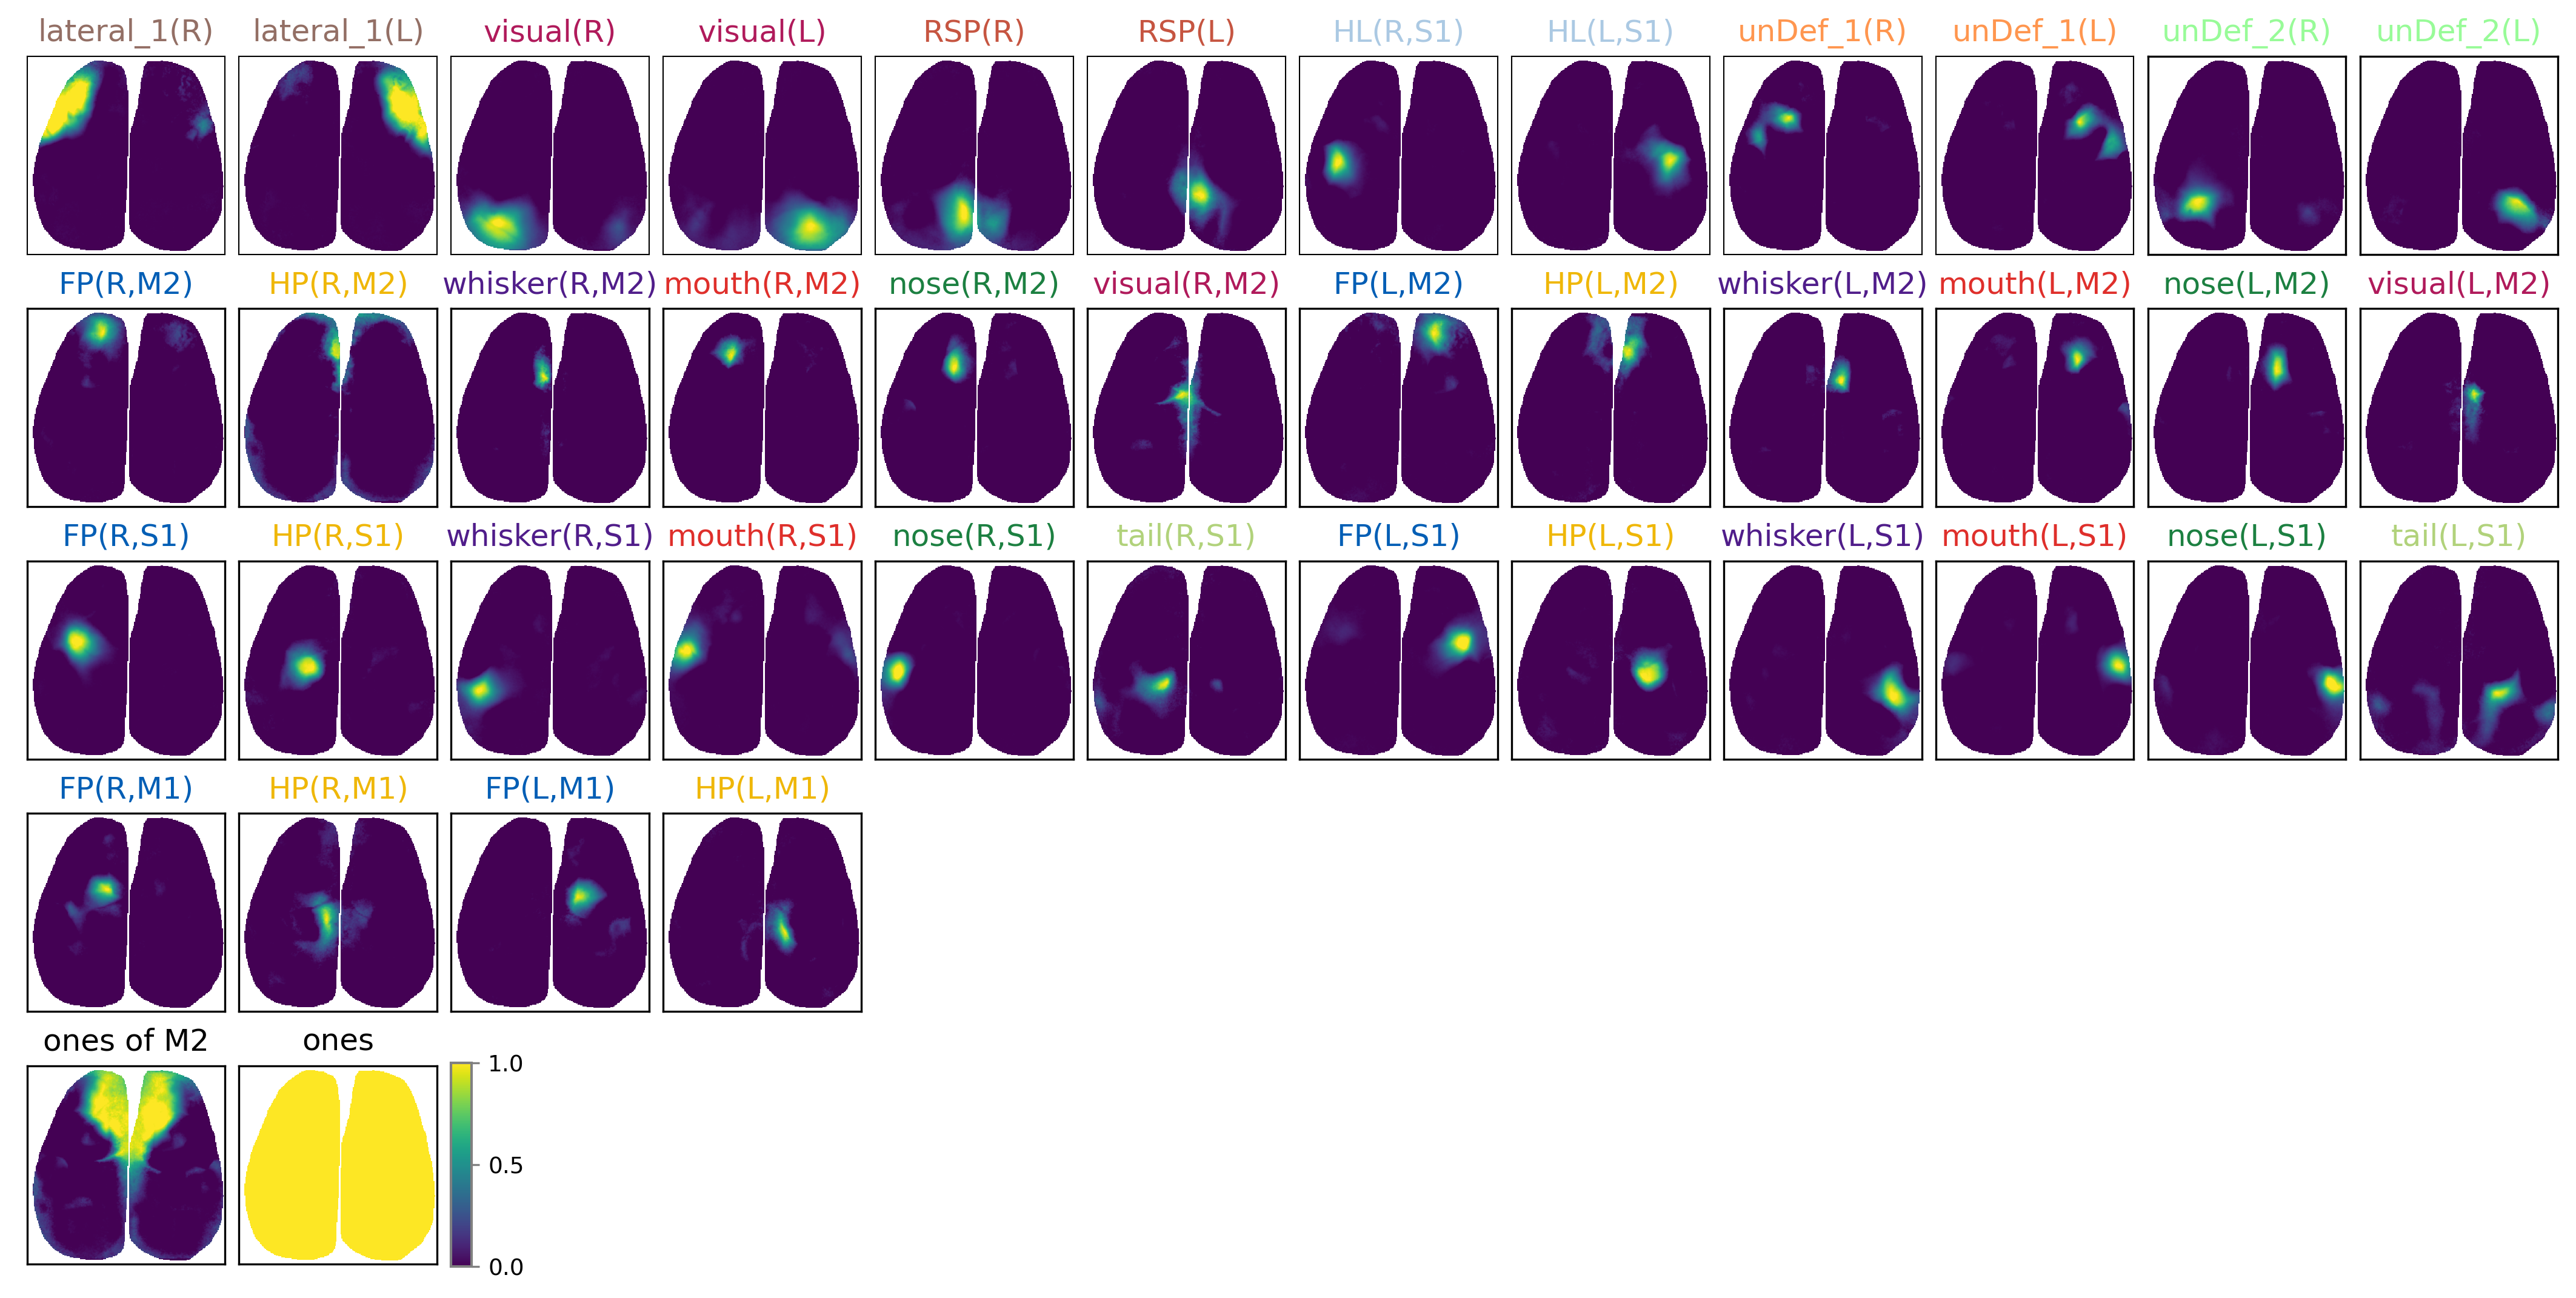

In [42]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_extra)):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_extra),len(all_bdps_M2)+len(all_bdps_extra)):
    exec("ax{} = fig.add_subplot(gs[y_offset+6:y_offset+11,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)):
    exec("ax{} = fig.add_subplot(gs[y_offset+12:y_offset+17,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1)):
    exec("ax{} = fig.add_subplot(gs[y_offset+18:y_offset+23,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1)+2):
    exec("ax{} = fig.add_subplot(gs[y_offset+24:y_offset+29,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
    
ax999 = fig.add_subplot(gs[y_offset+24:y_offset+29,x_start:x_start+1])

##########################################
##########################################
for i_key,key in enumerate(all_bdps_extra):
    ind_in_list = all_bdps.index(key)
    W_masked_2show = W_masked[:,:,ind_in_list]        
    exec("ax{}.imshow(W_masked_2show,vmin=0,vmax=1)".format(i_key))
    c = palatte_dict[key.split('_')[0]]
    c = palatte_dict[key]
    exec("ax{}.set_title(body_part_short_dict[key],color=c)".format(i_key))
    # plt.axis('off')
for i_key,key in enumerate(all_bdps_M2):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    c = palatte_dict[key.split('_')[0].replace('L','R')]
    exec("ax{}.set_title(body_part_short_dict[key.split('_')[0]+'_']+key.split('_')[1]+')',color=c)".format(i_entry))

for i_key,key in enumerate(all_bdps_S1):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)+len(all_bdps_M2)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    c = palatte_dict[key.split('_')[0].replace('L','R')]
    exec("ax{}.set_title(body_part_short_dict[key.split('_')[0]+'_']+key.split('_')[1]+')',color=c)".format(i_entry))

for i_key,key in enumerate(all_bdps_M1):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    c = palatte_dict[key.split('_')[0].replace('L','R')]
    exec("ax{}.set_title(body_part_short_dict[key.split('_')[0]+'_']+key.split('_')[1]+')',color=c)".format(i_entry))

# plot median
i_entry = len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)+len(all_bdps_M1)
exec("sbp = ax{}.imshow(W_masked[:,:,-2],vmin=0,vmax=1)".format(i_entry))
exec("ax{}.set_title('ones of M2')".format(i_entry))
 
# plot 1
i_entry = len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)+len(all_bdps_M1)+1
exec("ax{}.imshow(W_masked[:,:,-1],vmin=0,vmax=0.1)".format(i_entry))
exec("ax{}.set_title('ones')".format(i_entry))

# for i_ax in range(50):
#     try:
#         exec("ax{}.axis('off')".format(i_ax))
#     except:
#         continue
        
for i_part,part in enumerate(['top','bottom','left','right']):
    for i_ax in range(10):
        try:
            exec("ax{}.spines[part].set_linewidth(0.5) ".format(i_ax))
        except:
            continue  

cb = fig.colorbar(sbp, cax=ax999,fraction=0.2,orientation='vertical');
cb.ax.tick_params(labelsize=9,length=3,color='gray')
cb.ax.yaxis.tick_right()       
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=2)
cb.locator = tick_locator
cb.update_ticks()
ax999.set_aspect(10)
ax999.set_anchor('W')
            
            
plt.subplots_adjust(wspace=0.5)
plt.savefig('figS8-P1-NNLS-spatial-components.svg',format='svg',dpi=300)